# Global Equity Index Lab: multivariable regression, 3D analysis and ML across 14 countries

**Question:** what drives the weekly returns of the world's stock indices, how much real
diversification do you get by spreading money across countries, and can machine learning
predict next week's move?

**How to run:** in VS Code click **Run All** (*Exécuter tout*), or in a Terminal use
`python global_index_lab.py`. Cells depend on each other, so always run them from top to bottom.
Charts are saved in `outputs/` (PNG for the README, interactive 3D `.html` you can rotate with the mouse).

*Educational project, not investment advice.*

In [1]:
import os
import sys
import warnings
import webbrowser
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

# ---- settings you may want to change ---------------------------------------------------------
SHOW_WINDOWS = False    # script mode only: True = open each matplotlib chart in a window
OPEN_HTML = True        # script mode only: open the interactive 3D pages in your browser at the end
REFRESH = False         # True = download prices again instead of using data/prices.csv
START = "2012-01-01"

try:                    # inside Jupyter / VS Code notebook?
    get_ipython()       # noqa: F821
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    if not SHOW_WINDOWS:
        matplotlib.use("Agg")

import matplotlib.pyplot as plt
import matplotlib.ticker
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    import yfinance as yf
except ImportError:
    raise ImportError("Missing package. In the Terminal run:  pip install yfinance plotly scikit-learn")
try:
    import plotly.graph_objects as go
except ImportError:
    go = None
    print("plotly is not installed, so the interactive 3D pages will be skipped.  pip install plotly")

warnings.filterwarnings("ignore")
if "__file__" in globals():                       # script mode: work next to this file
    os.chdir(Path(__file__).resolve().parent)
DATA, OUT = Path("data"), Path("outputs")
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
RNG = np.random.default_rng(7)
WEEKS = 52

# ---- universe --------------------------------------------------------------------------------
INDICES = {   # ticker: (country, region)
    "^GSPC": ("United States", "Americas"), "^GSPTSE": ("Canada", "Americas"),
    "^BVSP": ("Brazil", "Americas"), "^MXX": ("Mexico", "Americas"),
    "^FTSE": ("United Kingdom", "Europe"), "^GDAXI": ("Germany", "Europe"),
    "^FCHI": ("France", "Europe"), "XU100.IS": ("Turkey", "Europe"),
    "^N225": ("Japan", "Asia-Pacific"), "^HSI": ("Hong Kong", "Asia-Pacific"),
    "000001.SS": ("China", "Asia-Pacific"), "^NSEI": ("India", "Asia-Pacific"),
    "^KS11": ("South Korea", "Asia-Pacific"), "^AXJO": ("Australia", "Asia-Pacific"),
}
US = "^GSPC"
FACTORS = {   # ticker: (label, how to turn the price into a weekly change)
    "DX-Y.NYB": ("USD index", "ret"), "CL=F": ("Oil (WTI)", "ret"), "GC=F": ("Gold", "ret"),
    "^TNX": ("US 10y yield change", "diff"), "^VIX": ("VIX change", "logdiff"),
}
US_LABEL = "US equities (S&P 500)"
REGION_COLOR = {"Americas": "#2F6DB5", "Europe": "#D9822B", "Asia-Pacific": "#2A9D8F"}

# ---- the 3D regression-plane chart: which country, explained by which two drivers ------------
PLANE_TARGET = "^GDAXI"          # try "^N225", "^BVSP", "^GSPTSE" ...
PLANE_X1 = US_LABEL
PLANE_X2 = "VIX change"          # try "USD index", "Oil (WTI)", "Gold", "US 10y yield change"


def finish(fig, name):
    fig.savefig(OUT / name, dpi=150, bbox_inches="tight", facecolor="white")
    if IN_NOTEBOOK or SHOW_WINDOWS:
        plt.show()
    else:
        plt.close(fig)


HTML_PAGES = []


def save_html(fig, name):
    if go is None:
        return
    fig.write_html(OUT / name, include_plotlyjs="cdn")
    HTML_PAGES.append(OUT / name)
    if IN_NOTEBOOK:
        try:
            fig.show()
        except Exception as e:          # plotly renderer missing: the .html file still works
            print(f"(could not display inline: {type(e).__name__}; open outputs/{name} instead)")


def show_md(text):
    if IN_NOTEBOOK:
        from IPython.display import Markdown, display
        display(Markdown(text))
    else:
        print(text)


def show_df(df, digits=2):
    if IN_NOTEBOOK:
        from IPython.display import display
        display(df.round(digits))
    else:
        print(df.round(digits).to_string())


print(f"Ready. Notebook mode: {IN_NOTEBOOK}. Outputs go to: {OUT.resolve()}")

Ready. Notebook mode: True. Outputs go to: /Users/hamzaelmadmad/Documents/Academics/Online Courses/Coursera /Python for finance/global-index-lab/outputs


## 1. Data
14 national stock indices (3 regions) and 5 global drivers: the US dollar, oil, gold, the US 10-year
yield and the VIX. Daily prices from Yahoo Finance are cached in `data/prices.csv`, then converted to
**weekly (Friday) returns**. Weekly data reduces the problem that markets close at different hours
(Tokyo closes before New York opens).

In [2]:
ALL = list(INDICES) + list(FACTORS)
cache = DATA / "prices.csv"

px = None
if cache.exists() and not REFRESH:
    px = pd.read_csv(cache, index_col=0, parse_dates=True)
    if px.shape[0] < 500 or px.notna().any().sum() < 8:        # empty or broken cache: ignore it
        print("The cached file data/prices.csv is empty or incomplete, so it will be downloaded again.")
        px = None
    else:
        print(f"Loaded cached prices: {px.shape[0]:,} days x {px.shape[1]} series")
if px is None:
    print("Downloading from Yahoo Finance (about a minute)...")
    raw = yf.download(ALL, start=START, auto_adjust=True, progress=False)
    if raw is None or raw.empty or "Close" not in raw:
        raise RuntimeError("Yahoo Finance returned no data. Check your internet connection (or VPN) and run again.")
    px = raw["Close"].copy()
    idx = pd.to_datetime(px.index)
    px.index = idx.tz_localize(None) if idx.tz is not None else idx
    if px.shape[0] < 500 or px.notna().any().sum() < 8:
        raise RuntimeError("Yahoo Finance returned almost no data, so nothing was saved. "
                           "Check your internet connection (or VPN) and run again.")
    px.to_csv(cache)
    print(f"Downloaded and cached: {px.shape[0]:,} days x {px.shape[1]} series")

# drop series that failed or have too little history
ok = [c for c in px.columns if px[c].notna().mean() >= 0.6]
dropped = [c for c in ALL if c not in ok]
if dropped:
    print("WARNING, no usable data for:", dropped, "(they are removed from the analysis)")
INDICES = {k: v for k, v in INDICES.items() if k in ok}
FACTORS = {k: v for k, v in FACTORS.items() if k in ok}
if US not in INDICES or len(INDICES) < 6:
    raise RuntimeError("Not enough index data downloaded. Check your internet connection and set REFRESH = True.")

px = px[ok].sort_index().ffill(limit=5)
wk = px.resample("W-FRI").last()

NAME = {k: v[0] for k, v in INDICES.items()}
REGION = {k: v[1] for k, v in INDICES.items()}
ret = wk[list(INDICES)].pct_change()

fac = pd.DataFrame(index=wk.index)
fac[US_LABEL] = ret[US]
for t, (label, how) in FACTORS.items():
    s = wk[t]
    if how == "ret":
        fac[label] = s.pct_change()
    elif how == "logdiff":
        fac[label] = np.log(s).diff()
    else:                                   # yield change; Yahoo sometimes quotes yields x10
        fac[label] = (s / 10 if s.median() > 20 else s).diff()

data = pd.concat([ret, fac.drop(columns=US_LABEL)], axis=1).dropna()
R = data[list(INDICES)]                                   # weekly index returns
F = pd.concat([R[US].rename(US_LABEL), data[[v[0] for v in FACTORS.values()]]], axis=1)   # drivers
others = [c for c in INDICES if c != US]
vix_level = wk["^VIX"].reindex(R.index) if "^VIX" in wk else None

print(f"Weekly sample: {R.index[0].date()} to {R.index[-1].date()}  ({len(R)} weeks, "
      f"{len(INDICES)} indices, {F.shape[1]} drivers)")

Downloaded and cached: 3,855 days x 19 series
Weekly sample: 2012-01-13 to 2026-10-16  (771 weeks, 14 indices, 6 drivers)


## 2. Risk and return by country
*Local-currency price indices, no dividends. The "beta" column is the slope against the S&P 500: a beta
of 1.2 means the index moved about 1.2% for each 1% move in the S&P 500.*

,Return % p.a.,Volatility % p.a.,Max drawdown %,Corr. with S&P,Beta to S&P,Return per risk
Country,,,,,,
Turkey,23.68,25.13,-32.71,0.28,0.46,0.94
United States,12.84,15.59,-31.81,1.00,1.00,0.82
India,11.27,15.23,-34.56,0.50,0.49,0.74
Japan,14.85,20.35,-31.37,0.59,0.77,0.73
Canada,7.61,13.34,-33.60,0.80,0.68,0.57
Germany,10.22,18.40,-35.03,0.69,0.82,0.56
South Korea,7.87,18.83,-39.17,0.53,0.64,0.42
Brazil,8.83,21.35,-43.89,0.49,0.67,0.41
Australia,5.28,13.23,-32.53,0.63,0.53,0.40


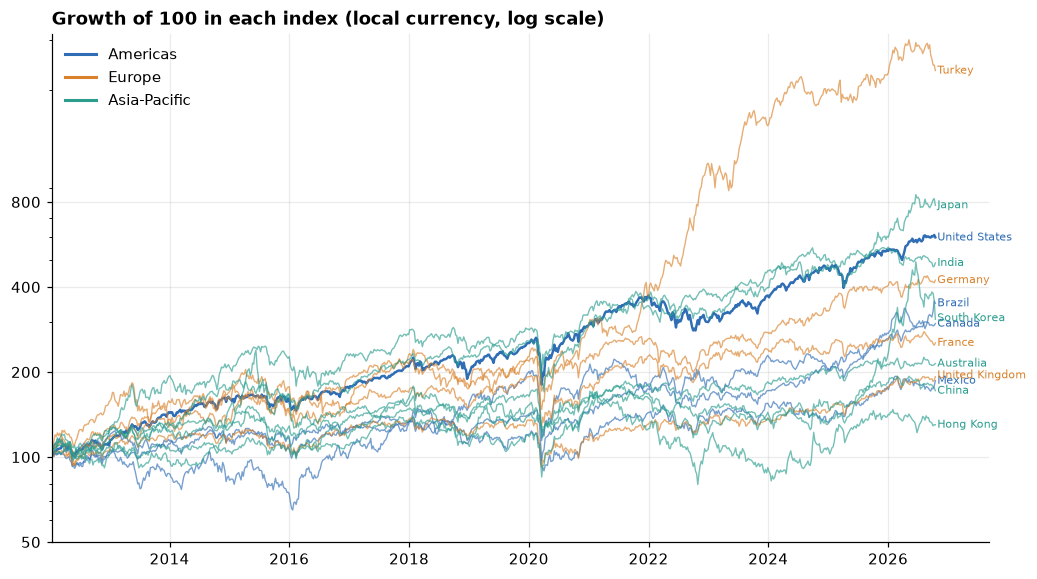

In [3]:
def max_drawdown(r):
    w = (1 + r).cumprod()
    return float((w / w.cummax() - 1).min())


rows = []
for t in INDICES:
    r = R[t]
    years = len(r) / WEEKS
    rows.append({
        "Country": NAME[t], "Region": REGION[t],
        "Return % p.a.": ((1 + r).prod() ** (1 / years) - 1) * 100,
        "Volatility % p.a.": r.std() * np.sqrt(WEEKS) * 100,
        "Max drawdown %": max_drawdown(r) * 100,
        "Corr. with S&P": r.corr(R[US]),
        "Beta to S&P": r.cov(R[US]) / R[US].var(),
    })
summary = pd.DataFrame(rows, index=list(INDICES))
summary["Return per risk"] = summary["Return % p.a."] / summary["Volatility % p.a."]
show_df(summary.set_index("Country").drop(columns="Region").sort_values("Return per risk", ascending=False))
summary.set_index("Country").to_csv(OUT / "summary_by_country.csv")

growth = (1 + R).cumprod() * 100
fig, ax = plt.subplots(figsize=(11, 6))
for t in INDICES:
    ax.plot(growth.index, growth[t], color=REGION_COLOR[REGION[t]], lw=1.6 if t == US else 0.9,
            alpha=1 if t == US else .65)
ends = growth.iloc[-1].sort_values()                      # spread the end labels so they do not overlap
pos, gap = [], 0.045
for v in np.log(ends.values):
    pos.append(v if not pos else max(v, pos[-1] + gap))
for (t, _), yv in zip(ends.items(), np.exp(pos)):
    ax.text(growth.index[-1] + pd.Timedelta(days=12), yv, NAME[t], fontsize=7.5, va="center",
            color=REGION_COLOR[REGION[t]])
ax.set_yscale("log")
ax.set_yticks([50, 100, 200, 400, 800])
ax.get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.get_yaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_ylim(top=max(pos and np.exp(pos[-1]) * 1.05, growth.max().max() * 1.05))
ax.set_title("Growth of 100 in each index (local currency, log scale)", loc="left", fontweight="bold")
ax.set_xlim(growth.index[0], growth.index[-1] + pd.Timedelta(days=330))
handles = [plt.Line2D([0], [0], color=c, lw=2, label=k) for k, c in REGION_COLOR.items()]
ax.legend(handles=handles, loc="upper left", frameon=False)
finish(fig, "01_growth_by_country.png")

## 3. Multivariable regression: what drives each country?
For every country we fit

`weekly return = a + b1·US equities + b2·USD + b3·Oil + b4·Gold + b5·Δ10y yield + b6·ΔVIX + error`

Returns and drivers are standardised, so each coefficient reads as *"standard deviations of this country's
move per one standard deviation of the driver"* and countries are directly comparable. Standard errors are
heteroskedasticity-robust (HC1). A star marks |t| > 2. VIF checks whether the drivers overlap too much.

Variance inflation factors (above ~5 means the drivers overlap too much):


,US equities (S&P 500),USD index,Oil (WTI),Gold,US 10y yield change,VIX change
VIF,2.58,1.41,1.09,1.38,1.2,2.41


Standardised coefficients:


,US equities (S&P 500),USD index,Oil (WTI),Gold,US 10y yield change,VIX change
Canada,0.70,0.07,0.15,0.17,-0.01,-0.08
Germany,0.52,0.03,-0.02,0.02,0.06,-0.24
France,0.51,0.01,-0.01,-0.01,0.07,-0.22
United Kingdom,0.45,0.09,0.10,0.07,0.01,-0.26
Australia,0.57,0.05,0.15,0.02,-0.09,-0.07
Japan,0.59,0.07,-0.04,-0.04,0.08,-0.03
Mexico,0.35,-0.09,0.09,-0.00,-0.05,-0.20
South Korea,0.42,-0.07,0.02,0.06,-0.02,-0.11
Brazil,0.38,-0.13,0.13,0.07,0.07,-0.05
India,0.44,-0.08,-0.04,-0.03,-0.00,-0.07


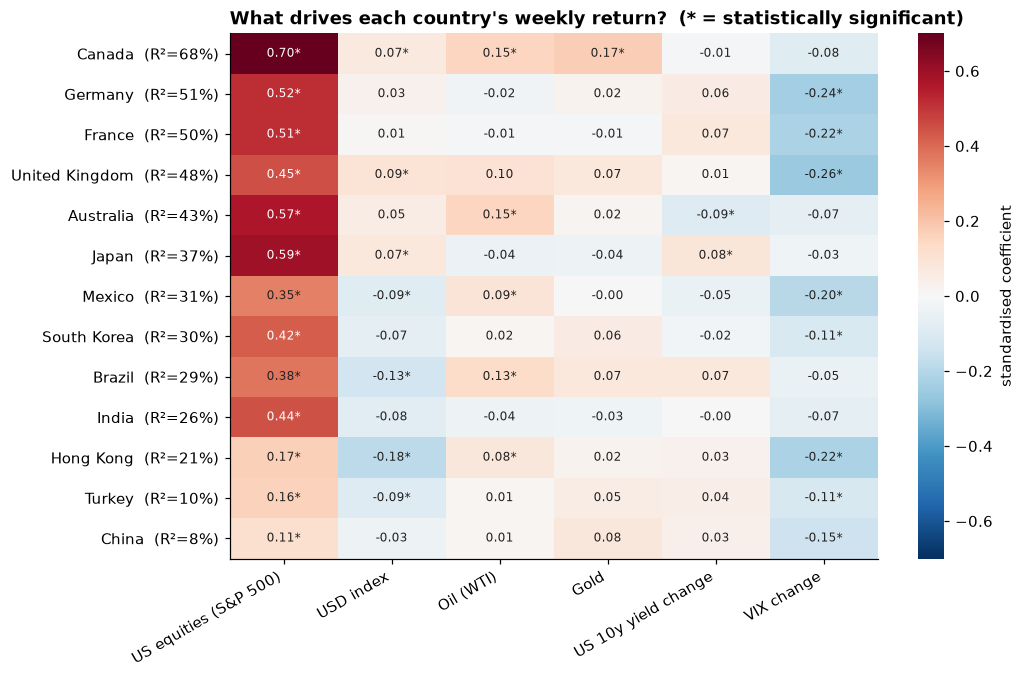

In [4]:
def ols(y, X):
    """OLS with an intercept and HC1 robust standard errors."""
    X1 = np.column_stack([np.ones(len(X)), X])
    n, k = X1.shape
    xtx_inv = np.linalg.inv(X1.T @ X1)
    b = xtx_inv @ X1.T @ y
    e = y - X1 @ b
    meat = (X1 * e[:, None]).T @ (X1 * e[:, None])
    cov = xtx_inv @ meat @ xtx_inv * n / (n - k)
    se = np.sqrt(np.diag(cov))
    t = b / se
    r2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
    return {"b": b, "se": se, "t": t, "p": 2 * stats.t.sf(np.abs(t), n - k),
            "r2": r2, "adj_r2": 1 - (1 - r2) * (n - 1) / (n - k), "n": n, "resid": e, "fitted": X1 @ b}


def zscore(df):
    return (df - df.mean()) / df.std()


Z = zscore(F)
vif = pd.Series({c: 1 / (1 - ols(Z[c].values, Z.drop(columns=c).values)["r2"]) for c in Z.columns}, name="VIF")
print("Variance inflation factors (above ~5 means the drivers overlap too much):")
show_df(vif.to_frame().T)

beta_std, tstat, r2 = {}, {}, {}
for c in others:
    res = ols(zscore(R[c]).values, Z.values)
    beta_std[NAME[c]] = res["b"][1:]
    tstat[NAME[c]] = res["t"][1:]
    r2[NAME[c]] = res["r2"]
beta_std = pd.DataFrame(beta_std, index=F.columns).T
tstat = pd.DataFrame(tstat, index=F.columns).T
r2 = pd.Series(r2, name="R2")

order = r2.sort_values(ascending=False).index
print("Standardised coefficients:")
show_df(beta_std.loc[order])
reg_out = beta_std.loc[order].add_prefix("beta: ").join(tstat.loc[order].add_prefix("t: ")).join(r2)
reg_out.to_csv(OUT / "regression_results.csv")

# heatmap
fig, ax = plt.subplots(figsize=(9.5, 6.2))
M = beta_std.loc[order].values
lim = np.abs(M).max()
im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(M.shape[1]))
ax.set_xticklabels(beta_std.columns, rotation=30, ha="right")
ax.set_yticks(range(M.shape[0]))
ax.set_yticklabels([f"{n}  (R²={r2[n]:.0%})" for n in order])
ax.grid(False)
for i, n in enumerate(order):
    for j, col in enumerate(beta_std.columns):
        star = "*" if abs(tstat.loc[n, col]) > 2 else ""
        ax.text(j, i, f"{M[i, j]:.2f}{star}", ha="center", va="center", fontsize=8,
                color="white" if abs(M[i, j]) > .55 * lim else "#222")
fig.colorbar(im, ax=ax, label="standardised coefficient").outline.set_visible(False)
ax.set_title("What drives each country's weekly return?  (* = statistically significant)",
             loc="left", fontweight="bold")
finish(fig, "02_driver_heatmap.png")

## 4. 3D chart #1: the regression plane
This is the classic multivariable-regression picture. Each dot is one week. Two drivers sit on the floor axes,
the country's return is the height, and the grey-blue sheet is the fitted plane `y = a + b1·x1 + b2·x2`.
Dots are coloured by their residual (how far they sit above or below the plane).

Germany = 0.07 + 0.59 x US equities + -0.04 x VIX change    R² = 50.6%, n = 771
t-stats: US equities 6.7, VIX change -4.8


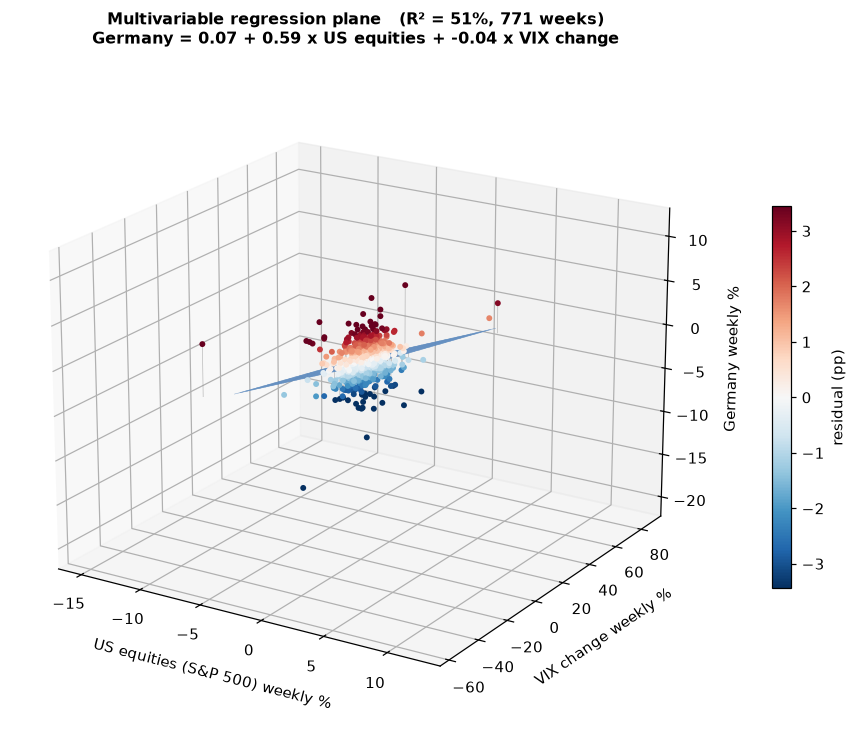

(could not display inline: ValueError; open outputs/3d_regression_plane.html instead)


In [5]:
tgt = PLANE_TARGET if PLANE_TARGET in INDICES else others[0]
if PLANE_X1 not in F or PLANE_X2 not in F:
    raise KeyError(f"PLANE_X1/PLANE_X2 must be one of: {list(F.columns)}")
y = R[tgt].values * 100
x1 = F[PLANE_X1].values * 100
x2 = F[PLANE_X2].values * 100
pl = ols(y, np.column_stack([x1, x2]))
b0, b1, b2 = pl["b"]
unit2 = "pp" if "yield" in PLANE_X2 else "%"
eq = f"{NAME[tgt]} = {b0:.2f} + {b1:.2f} x {PLANE_X1.split(' (')[0]} + {b2:.2f} x {PLANE_X2}"
print(eq, f"   R² = {pl['r2']:.1%}, n = {pl['n']}")
print(f"t-stats: {PLANE_X1.split(' (')[0]} {pl['t'][1]:.1f}, {PLANE_X2} {pl['t'][2]:.1f}")

gx = np.linspace(*np.percentile(x1, [1, 99]), 24)
gy = np.linspace(*np.percentile(x2, [1, 99]), 24)
GX, GY = np.meshgrid(gx, gy)
GZ = b0 + b1 * GX + b2 * GY
resid = pl["resid"]
m = np.percentile(np.abs(resid), 95)

fig = plt.figure(figsize=(10.5, 8.2))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(GX, GY, GZ, color="#8fb4dd", alpha=.38, edgecolor="#5f8dc2", linewidth=.3, antialiased=True)
for i in RNG.choice(len(y), size=min(160, len(y)), replace=False):       # drop-lines to the plane
    ax.plot([x1[i]] * 2, [x2[i]] * 2, [y[i], pl["fitted"][i]], color="#888", lw=.45, alpha=.55)
sc = ax.scatter(x1, x2, y, c=resid, cmap="RdBu_r", vmin=-m, vmax=m, s=15, depthshade=False,
                edgecolors="none")
ax.set_xlabel(f"{PLANE_X1} weekly %", labelpad=8)
ax.set_ylabel(f"{PLANE_X2} weekly %", labelpad=8)
ax.set_zlabel(f"{NAME[tgt]} weekly %", labelpad=6)
ax.view_init(elev=20, azim=-58)
ax.set_title(f"Multivariable regression plane   (R² = {pl['r2']:.0%}, {pl['n']} weeks)\n{eq}",
             fontsize=10.5, fontweight="bold")
fig.colorbar(sc, ax=ax, shrink=.55, pad=.08, label="residual (pp)")
finish(fig, "03_3d_regression_plane.png")

if go is not None:
    f2 = go.Figure()
    f2.add_trace(go.Surface(x=gx, y=gy, z=GZ, opacity=.45, showscale=False, name="OLS plane",
                            colorscale=[[0, "#8fb4dd"], [1, "#8fb4dd"]], hoverinfo="skip"))
    f2.add_trace(go.Scatter3d(
        x=x1, y=x2, z=y, mode="markers", name="weeks",
        marker=dict(size=3, color=resid, colorscale="RdBu_r", cmid=0, opacity=.85,
                    colorbar=dict(title="residual", len=.6)),
        text=[d.strftime("%Y-%m-%d") for d in R.index],
        hovertemplate="week ending %{text}<br>" + PLANE_X1 + ": %{x:.2f}%<br>" + PLANE_X2 +
                      ": %{y:.2f}%<br>" + NAME[tgt] + ": %{z:.2f}%<extra></extra>"))
    f2.update_layout(title=f"{eq}  (R² = {pl['r2']:.0%})", margin=dict(l=0, r=0, t=60, b=0),
                     scene=dict(xaxis_title=PLANE_X1, yaxis_title=PLANE_X2, zaxis_title=NAME[tgt]))
    save_html(f2, "3d_regression_plane.html")

## 5. 3D chart #2: the beta landscape
How sensitive is each country to the S&P 500, and has that changed through time? Each point is a **52-week
rolling beta**. Hills are periods where a market moved more than the US, valleys are periods where it was
decoupled.

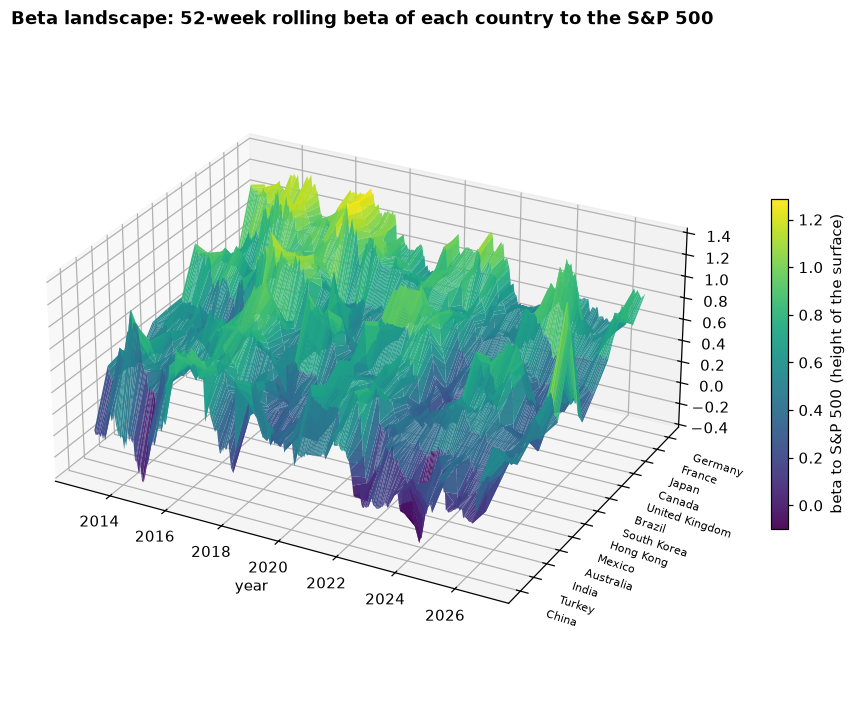

(could not display inline: ValueError; open outputs/3d_beta_surface.html instead)


In [6]:
roll = pd.DataFrame({NAME[c]: R[c].rolling(WEEKS).cov(R[US]) / R[US].rolling(WEEKS).var() for c in others})
roll = roll.dropna().iloc[::2]
order_b = roll.mean().sort_values().index.tolist()          # least to most sensitive
roll = roll[order_b]
years_dec = (roll.index.year + (roll.index.dayofyear - 1) / 365.25).values
ZZ = roll.values.T                                          # countries x time
XX, YY = np.meshgrid(years_dec, np.arange(len(order_b)))

fig = plt.figure(figsize=(11.5, 7.8))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(XX, YY, ZZ, cmap="viridis", linewidth=0, antialiased=True, alpha=.95, rstride=1, cstride=1)
ax.set_yticks(range(len(order_b)))
ax.set_yticklabels(order_b, fontsize=7, rotation=-18, ha="left")
ax.set_xlabel("year", labelpad=6)
ax.view_init(elev=27, azim=-62)
ax.set_box_aspect((1.9, 1.5, .85))
ax.set_title("Beta landscape: 52-week rolling beta of each country to the S&P 500", fontweight="bold")
fig.colorbar(surf, ax=ax, shrink=.5, pad=.08, label="beta to S&P 500 (height of the surface)")
finish(fig, "04_3d_beta_surface.png")

if go is not None:
    f2 = go.Figure(go.Surface(x=years_dec, y=np.arange(len(order_b)), z=ZZ, colorscale="Viridis",
                              colorbar=dict(title="beta"),
                              hovertemplate="year %{x:.2f}<br>beta %{z:.2f}<extra></extra>"))
    f2.update_layout(title="Rolling 52-week beta to the S&P 500", margin=dict(l=0, r=0, t=60, b=0),
                     scene=dict(xaxis_title="year", zaxis_title="beta",
                                yaxis=dict(title="", tickvals=list(range(len(order_b))), ticktext=order_b)))
    save_html(f2, "3d_beta_surface.html")

## 6. 3D chart #3: the risk map
Return, volatility and beta in one picture. The ideal country sits **high on return, low on volatility
and, for a diversifier, low on beta**.

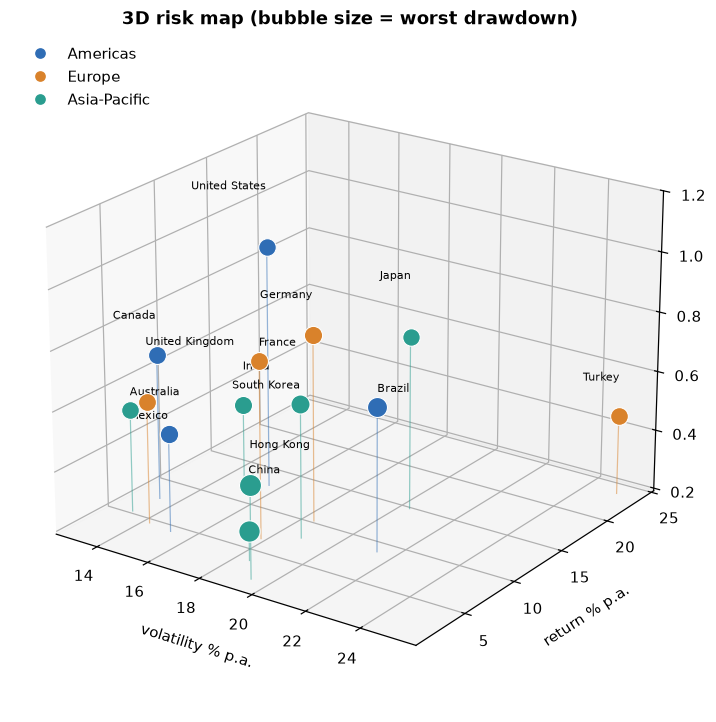

(could not display inline: ValueError; open outputs/3d_risk_map.html instead)


In [7]:
S = summary.copy()
fig = plt.figure(figsize=(10.5, 8))
ax = fig.add_subplot(111, projection="3d")
zmin = S["Beta to S&P"].min() - .1
for k, (t, r_) in enumerate(S.sort_values("Volatility % p.a.").iterrows()):
    col = REGION_COLOR[r_["Region"]]
    ax.plot([r_["Volatility % p.a."]] * 2, [r_["Return % p.a."]] * 2, [zmin, r_["Beta to S&P"]],
            color=col, lw=.8, alpha=.5)
    ax.scatter(r_["Volatility % p.a."], r_["Return % p.a."], r_["Beta to S&P"],
               s=30 + abs(r_["Max drawdown %"]) * 3.2, color=col, edgecolors="white", linewidths=.7,
               depthshade=False)
    ax.text(r_["Volatility % p.a."], r_["Return % p.a."], r_["Beta to S&P"] + .05 + .07 * (k % 3),
            r_["Country"], fontsize=7.5, ha="left" if k % 2 == 0 else "right")
ax.set_xlabel("volatility % p.a.", labelpad=8)
ax.set_ylabel("return % p.a.", labelpad=8)
ax.set_zlabel("beta to S&P 500", labelpad=6)
ax.set_zlim(zmin, S["Beta to S&P"].max() + .2)
ax.view_init(elev=22, azim=-55)
ax.legend(handles=[plt.Line2D([0], [0], marker="o", ls="", color=c, label=k) for k, c in REGION_COLOR.items()],
          loc="upper left", frameon=False)
ax.set_title("3D risk map (bubble size = worst drawdown)", fontweight="bold")
finish(fig, "05_3d_risk_map.png")

if go is not None:
    f2 = go.Figure()
    for reg, col in REGION_COLOR.items():
        d = S[S["Region"] == reg]
        f2.add_trace(go.Scatter3d(
            x=d["Volatility % p.a."], y=d["Return % p.a."], z=d["Beta to S&P"], mode="markers+text",
            text=d["Country"], textposition="top center", name=reg,
            marker=dict(size=6 + d["Max drawdown %"].abs() / 6, color=col, line=dict(color="white", width=1)),
            customdata=np.column_stack([d["Max drawdown %"], d["Corr. with S&P"]]),
            hovertemplate="<b>%{text}</b><br>vol %{x:.1f}%<br>return %{y:.1f}%<br>beta %{z:.2f}"
                          "<br>max drawdown %{customdata[0]:.0f}%<br>corr %{customdata[1]:.2f}<extra></extra>"))
    f2.update_layout(title="Risk map: volatility, return and beta", margin=dict(l=0, r=0, t=60, b=0),
                     scene=dict(xaxis_title="volatility % p.a.", yaxis_title="return % p.a.",
                                zaxis_title="beta to S&P 500"))
    save_html(f2, "3d_risk_map.html")

## 7. 3D chart #4: the hidden structure of world markets (PCA)
Principal component analysis finds the few "global forces" behind all 14 indices. **PC1 is the global
market factor.** Countries that sit close together in this 3D space move together; clusters reveal regional
blocs, and the outliers are your real diversifiers.

Share of weekly variance explained: PC1 52%, PC2 8%, PC3 7% (first three together 67%)


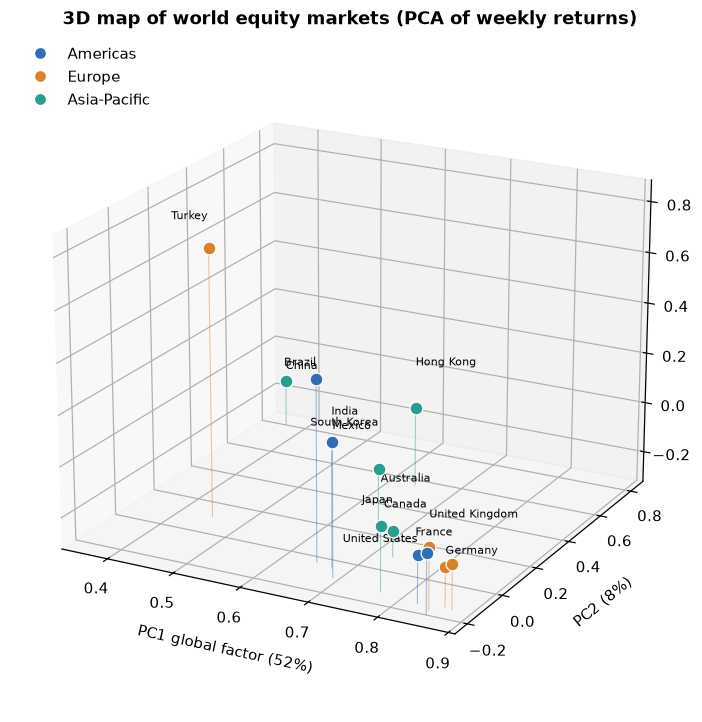

(could not display inline: ValueError; open outputs/3d_pca_map.html instead)


In [8]:
Zi = zscore(R)
corr_m = np.corrcoef(Zi.values.T)
vals, vecs = np.linalg.eigh(corr_m)
o = np.argsort(vals)[::-1]
vals, vecs = vals[o], vecs[:, o]
load = vecs * np.sqrt(vals)                      # correlation of each index with each component
explained = vals / vals.sum()
if load[:, 0].sum() < 0:
    load[:, 0] *= -1
for k in (1, 2):                                  # make the signs deterministic
    if load[np.abs(load[:, k]).argmax(), k] < 0:
        load[:, k] *= -1
L = pd.DataFrame(load[:, :3], index=[NAME[c] for c in R.columns], columns=["PC1", "PC2", "PC3"])
L["Region"] = [REGION[c] for c in R.columns]
print("Share of weekly variance explained:", ", ".join(f"PC{i + 1} {explained[i]:.0%}" for i in range(3)),
      f"(first three together {explained[:3].sum():.0%})")

fig = plt.figure(figsize=(10.5, 8))
ax = fig.add_subplot(111, projection="3d")
for k, (nm, r_) in enumerate(L.sort_values("PC1").iterrows()):
    col = REGION_COLOR[r_["Region"]]
    ax.plot([r_["PC1"]] * 2, [r_["PC2"]] * 2, [L["PC3"].min() - .1, r_["PC3"]], color=col, lw=.7, alpha=.45)
    ax.scatter(r_["PC1"], r_["PC2"], r_["PC3"], s=70, color=col, edgecolors="white", linewidths=.8, depthshade=False)
    ax.text(r_["PC1"], r_["PC2"], r_["PC3"] + .05 + .06 * (k % 3), nm,
            fontsize=7.5, ha="left" if k % 2 == 0 else "right")
ax.set_xlabel(f"PC1 global factor ({explained[0]:.0%})", labelpad=8)
ax.set_ylabel(f"PC2 ({explained[1]:.0%})", labelpad=8)
ax.set_zlabel(f"PC3 ({explained[2]:.0%})", labelpad=6)
ax.set_zlim(L["PC3"].min() - .1, L["PC3"].max() + .15)
ax.view_init(elev=20, azim=-62)
ax.legend(handles=[plt.Line2D([0], [0], marker="o", ls="", color=c, label=k) for k, c in REGION_COLOR.items()],
          loc="upper left", frameon=False)
ax.set_title("3D map of world equity markets (PCA of weekly returns)", fontweight="bold")
finish(fig, "06_3d_pca_map.png")

if go is not None:
    f2 = go.Figure()
    for reg, col in REGION_COLOR.items():
        d = L[L["Region"] == reg]
        f2.add_trace(go.Scatter3d(x=d["PC1"], y=d["PC2"], z=d["PC3"], mode="markers+text", text=d.index,
                                  textposition="top center", name=reg,
                                  marker=dict(size=8, color=col, line=dict(color="white", width=1))))
    f2.update_layout(title="PCA map of world equity markets", margin=dict(l=0, r=0, t=60, b=0),
                     scene=dict(xaxis_title=f"PC1 global ({explained[0]:.0%})",
                                yaxis_title=f"PC2 ({explained[1]:.0%})", zaxis_title=f"PC3 ({explained[2]:.0%})"))
    save_html(f2, "3d_pca_map.html")

## 8. Does diversification survive a crisis?
We split the weeks into **calm** and **stress** (VIX level in its top 20%) and compare each country's
correlation with the S&P 500 in the two regimes.

Stress weeks: 155 of 771.  Average pairwise correlation: calm 0.36 -> stress 0.61


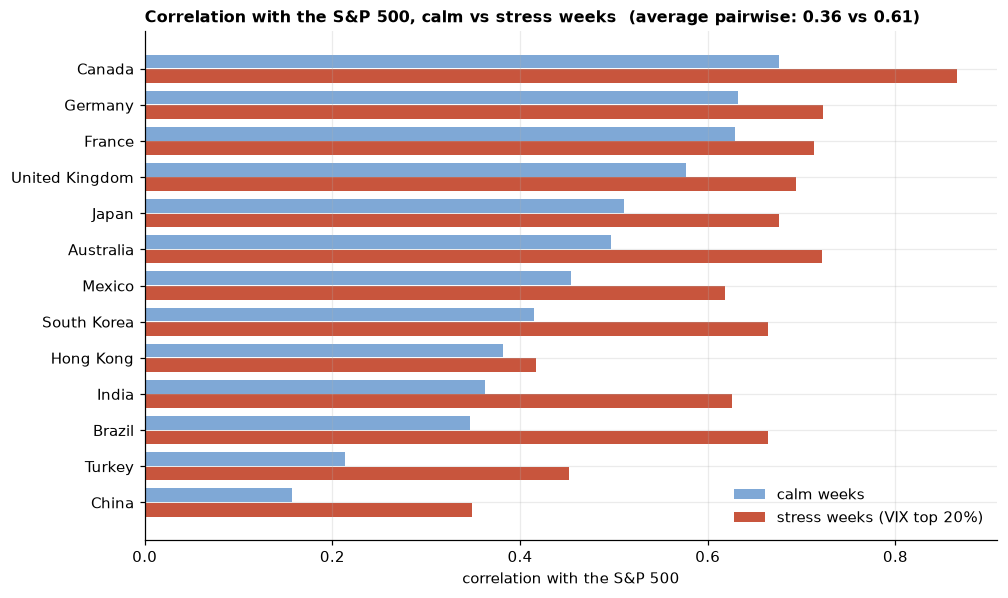

In [9]:
if vix_level is not None and vix_level.notna().sum() > 100:
    thr = vix_level.quantile(.8)
    stress = vix_level >= thr
else:                                   # fallback: the 20% worst US weeks
    stress = R[US] <= R[US].quantile(.2)
    thr = np.nan


def avg_pair_corr(df):
    c = df.corr().values
    return c[np.triu_indices_from(c, 1)].mean()


calm_c = R[~stress].corrwith(R.loc[~stress, US]).drop(US)
strs_c = R[stress].corrwith(R.loc[stress, US]).drop(US)
ap_calm, ap_stress = avg_pair_corr(R[~stress]), avg_pair_corr(R[stress])
print(f"Stress weeks: {int(stress.sum())} of {len(R)}.  Average pairwise correlation: "
      f"calm {ap_calm:.2f} -> stress {ap_stress:.2f}")

cmp_ = pd.DataFrame({"calm": calm_c.values, "stress": strs_c.values}, index=[NAME[c] for c in calm_c.index])
cmp_ = cmp_.sort_values("calm")
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(cmp_))
ax.barh(yy + .2, cmp_["calm"], height=.38, color="#7FA8D6", label="calm weeks")
ax.barh(yy - .2, cmp_["stress"], height=.38, color="#C8553D", label="stress weeks (VIX top 20%)")
ax.set_yticks(yy)
ax.set_yticklabels(cmp_.index)
ax.set_xlabel("correlation with the S&P 500")
ax.set_title(f"Correlation with the S&P 500, calm vs stress weeks  "
             f"(average pairwise: {ap_calm:.2f} vs {ap_stress:.2f})", loc="left", fontweight="bold", fontsize=10.5)
ax.legend(frameon=False, loc="lower right")
finish(fig, "07_calm_vs_stress_correlation.png")

## 9. Machine learning: explaining the present vs predicting the future
A walk-forward test (re-fit every 26 weeks, only on past data, first 5 years used for training):
* **Nowcast** - explain this week's return from this week's drivers (Ridge regression).
* **Predict** - forecast next week's return from this week's information (Ridge and Random Forest).

The score is **out-of-sample R² vs the historical mean**: 0 means "no better than guessing the average",
negative means worse than guessing.

,Nowcast (Ridge),Predict next week (Ridge),Predict next week (Random Forest)
Turkey,6.0,-3.4,-1.5
China,9.5,-5.7,-1.8
Hong Kong,19.2,0.8,0.4
India,24.9,-0.7,-2.9
Brazil,26.2,-5.4,-1.8
South Korea,26.5,1.2,1.0
Mexico,29.2,-2.9,-2.8
Japan,34.6,-0.2,0.2
United Kingdom,39.6,-3.9,-0.4
Australia,42.5,0.2,1.4


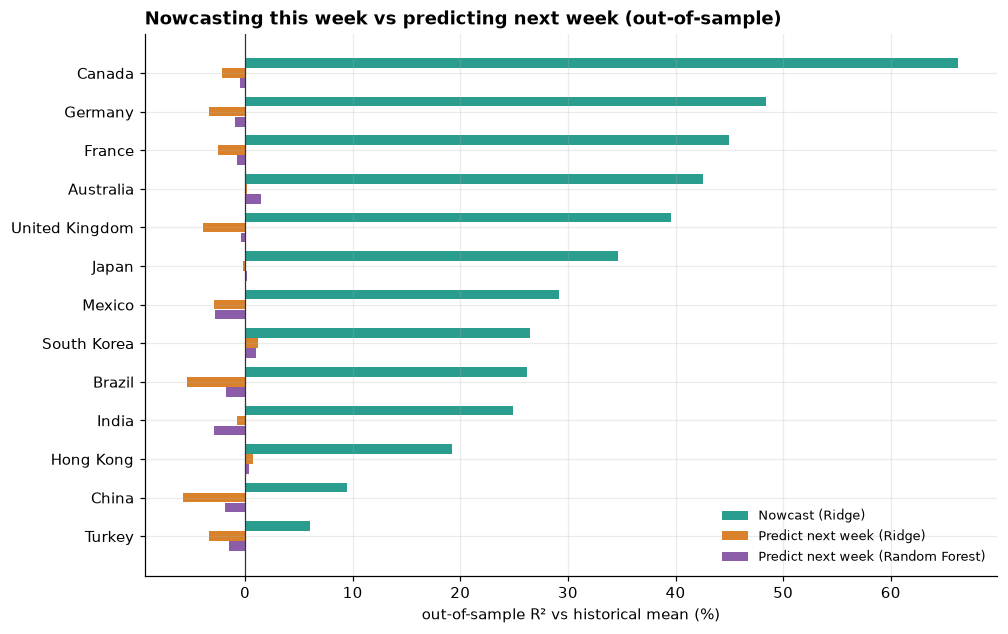

In [10]:
def ridge():
    return Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=50.0))])


def forest():
    return RandomForestRegressor(n_estimators=150, max_depth=4, min_samples_leaf=10, n_jobs=-1, random_state=7)


def walk_forward(y, X, make, start=260, step=26):
    pred = pd.Series(np.nan, index=y.index)
    base = pd.Series(np.nan, index=y.index)
    for s in range(start, len(y), step):
        e = min(s + step, len(y))
        mdl = make()
        mdl.fit(X.iloc[:s], y.iloc[:s])
        pred.iloc[s:e] = mdl.predict(X.iloc[s:e])
        base.iloc[s:e] = y.iloc[:s].mean()
    ok_ = pred.notna()
    return 1 - ((y[ok_] - pred[ok_]) ** 2).sum() / ((y[ok_] - base[ok_]) ** 2).sum()


X_now = F                                                              # same-week drivers
X_lag = pd.concat([R.add_prefix("lag_"), F.add_prefix("lag_f_")], axis=1).shift(1)
valid = X_lag.dropna().index
ml_rows = {}
min_len = 260 + 52
if len(valid) < min_len:
    print("Not enough history for the walk-forward test (need ~6 years of weekly data).")
else:
    for c in others:
        yy_ = R[c]
        ml_rows[NAME[c]] = {
            "Nowcast (Ridge)": walk_forward(yy_.loc[valid], X_now.loc[valid], ridge),
            "Predict next week (Ridge)": walk_forward(yy_.loc[valid], X_lag.loc[valid], ridge),
            "Predict next week (Random Forest)": walk_forward(yy_.loc[valid], X_lag.loc[valid], forest),
        }
    ml = pd.DataFrame(ml_rows).T.sort_values("Nowcast (Ridge)")
    show_df(ml * 100, 1)
    ml.to_csv(OUT / "ml_out_of_sample_r2.csv")

    fig, ax = plt.subplots(figsize=(10, 6.4))
    yy = np.arange(len(ml))
    for k, (col, colr) in enumerate([("Nowcast (Ridge)", "#2A9D8F"),
                                     ("Predict next week (Ridge)", "#D9822B"),
                                     ("Predict next week (Random Forest)", "#8B5CA8")]):
        ax.barh(yy + (1 - k) * .26, ml[col] * 100, height=.25, color=colr, label=col)
    ax.axvline(0, color="#333", lw=.8)
    ax.set_yticks(yy)
    ax.set_yticklabels(ml.index)
    ax.set_xlabel("out-of-sample R² vs historical mean (%)")
    ax.set_title("Nowcasting this week vs predicting next week (out-of-sample)", loc="left", fontweight="bold")
    ax.legend(frameon=False, loc="lower right", fontsize=8.5)
    finish(fig, "08_nowcast_vs_prediction.png")

## 10. Analyst memo
Written from the results above, so the commentary always matches the numbers.

In [11]:
S_oth = summary.loc[others].set_index("Country")
hi_b, lo_b = S_oth["Beta to S&P"].idxmax(), S_oth["Beta to S&P"].idxmin()
lo_c = S_oth["Corr. with S&P"].idxmin()
hi_r2, lo_r2 = r2.idxmax(), r2.idxmin()
best_rr = summary.set_index("Country")["Return per risk"].idxmax()
top_driver = beta_std.drop(columns=US_LABEL).abs().mean().idxmax()
spx_dominant = int((beta_std.abs().idxmax(axis=1) == US_LABEL).sum())
enb = float(vals.sum() ** 2 / (vals ** 2).sum())            # effective number of independent bets

if ap_stress > ap_calm + 0.03:
    stress_txt = (f"during high-VIX weeks the average pairwise correlation **rises from {ap_calm:.2f} to "
                  f"{ap_stress:.2f}**, so diversification across countries weakens exactly when markets fall")
elif ap_stress < ap_calm - 0.03:
    stress_txt = (f"in high-VIX weeks the average pairwise correlation **falls from {ap_calm:.2f} to "
                  f"{ap_stress:.2f}** in this sample")
else:
    stress_txt = (f"the average pairwise correlation is **similar in calm and stress weeks "
                  f"({ap_calm:.2f} vs {ap_stress:.2f})** in this sample")

if ml_rows:
    pred_cols = ["Predict next week (Ridge)", "Predict next week (Random Forest)"]
    best_pred = float(ml[pred_cols].max().max())
    best_pred_name = ml[pred_cols].max(axis=1).idxmax()
    now_med = float(ml["Nowcast (Ridge)"].median())
    pos_pred = int((ml[pred_cols].max(axis=1) > 0.01).sum())
    verdict = ("so the models work as a **risk-attribution tool, not as a trading signal**"
               if pos_pred <= len(ml) // 3 else "so there may be some modest, testable predictability, "
               "which should be confirmed with costs and a longer sample before any use")
    ml_txt = (f"- **Explaining versus predicting.** Out-of-sample, this week's drivers explain a median "
              f"{now_med:.0%} of a country's weekly return, but next-week forecasts reach at best "
              f"{best_pred:.1%} ({best_pred_name}), and {pos_pred} of {len(ml)} countries show a gain above 1%; "
              f"{verdict}.")
else:
    ml_txt = "- Walk-forward ML test skipped (not enough history)."

memo = f"""### Global Equity Index Lab: analyst memo
*Sample: {R.index[0].date()} to {R.index[-1].date()}, {len(R)} weekly observations, {len(INDICES)} national
indices in local currency, {len(FACTORS)} global drivers.*

**Bottom line.** One global factor explains **{explained[0]:.0%}** of the weekly variance of the
{len(INDICES)} indices, and {stress_txt}. The {len(INDICES)} markets behave like roughly **{enb:.1f} independent
bets**, not {len(INDICES)}.

**What the regression says**
- The S&P 500 is the largest single driver for {spx_dominant} of {len(others)} countries. Among the other
  drivers, the one with the biggest average influence is **{top_driver}**.
- Most market-sensitive to the US: **{hi_b}** (beta {S_oth['Beta to S&P'].max():.2f}). Least sensitive:
  **{lo_b}** (beta {S_oth['Beta to S&P'].min():.2f}). Lowest correlation with the US: **{lo_c}**
  ({S_oth['Corr. with S&P'].min():.2f}).
- Best explained by the model: **{hi_r2}** (R² {r2.max():.0%}). Least explained: **{lo_r2}**
  (R² {r2.min():.0%}), so its moves are driven mostly by local factors, which is both its risk and its
  diversification value.
- Best return per unit of risk over the sample: **{best_rr}** ({summary['Return per risk'].max():.2f}).
{ml_txt}

**What a portfolio manager should take from this**
1. Count **independent bets, not countries**: about {enb:.1f} effective bets across {len(INDICES)} indices.
2. For diversification look at the low-correlation markets above, but check their stress-period correlation
   first (chart 07), because that is when the benefit is tested.
3. Size positions by beta to the S&P 500 when hedging with index futures, and re-estimate regularly: the beta
   landscape (chart 04) shows the sensitivities move through time.
4. Use the currency, commodity and rate drivers (USD, oil, gold, US yields, VIX) as risk factors in the risk
   report, not as forecasting inputs.

**Limitations**
- Returns are in **local currency**: a dollar investor also takes currency risk (the USD driver only partly
  captures it).
- Price indices exclude dividends. Time-zone effects are reduced, not removed, by using weekly data.
- Regressions describe the past {len(R) / WEEKS:.0f} years only; relationships change across regimes.
- Educational project, **not investment advice**.
"""
show_md(memo)
(OUT / "analyst_memo.md").write_text(memo, encoding="utf-8")

### Global Equity Index Lab: analyst memo
*Sample: 2012-01-13 to 2026-10-16, 771 weekly observations, 14 national
indices in local currency, 5 global drivers.*

**Bottom line.** One global factor explains **52%** of the weekly variance of the
14 indices, and during high-VIX weeks the average pairwise correlation **rises from 0.36 to 0.61**, so diversification across countries weakens exactly when markets fall. The 14 markets behave like roughly **3.4 independent
bets**, not 14.

**What the regression says**
- The S&P 500 is the largest single driver for 11 of 13 countries. Among the other
  drivers, the one with the biggest average influence is **VIX change**.
- Most market-sensitive to the US: **Germany** (beta 0.82). Least sensitive:
  **China** (beta 0.29). Lowest correlation with the US: **China**
  (0.25).
- Best explained by the model: **Canada** (R² 68%). Least explained: **China**
  (R² 8%), so its moves are driven mostly by local factors, which is both its risk and its
  diversification value.
- Best return per unit of risk over the sample: **Turkey** (0.94).
- **Explaining versus predicting.** Out-of-sample, this week's drivers explain a median 29% of a country's weekly return, but next-week forecasts reach at best 1.4% (Australia), and 2 of 13 countries show a gain above 1%; so the models work as a **risk-attribution tool, not as a trading signal**.

**What a portfolio manager should take from this**
1. Count **independent bets, not countries**: about 3.4 effective bets across 14 indices.
2. For diversification look at the low-correlation markets above, but check their stress-period correlation
   first (chart 07), because that is when the benefit is tested.
3. Size positions by beta to the S&P 500 when hedging with index futures, and re-estimate regularly: the beta
   landscape (chart 04) shows the sensitivities move through time.
4. Use the currency, commodity and rate drivers (USD, oil, gold, US yields, VIX) as risk factors in the risk
   report, not as forecasting inputs.

**Limitations**
- Returns are in **local currency**: a dollar investor also takes currency risk (the USD driver only partly
  captures it).
- Price indices exclude dividends. Time-zone effects are reduced, not removed, by using weekly data.
- Regressions describe the past 15 years only; relationships change across regimes.
- Educational project, **not investment advice**.


2398

In [12]:
print("\nDone. Files in", OUT.resolve())
for p in sorted(OUT.iterdir()):
    print("  ", p.name)
if not IN_NOTEBOOK and OPEN_HTML and HTML_PAGES:
    for p in HTML_PAGES:
        try:
            webbrowser.open(p.resolve().as_uri())
        except Exception:
            pass


Done. Files in /Users/hamzaelmadmad/Documents/Academics/Online Courses/Coursera /Python for finance/global-index-lab/outputs
   01_growth_by_country.png
   02_driver_heatmap.png
   03_3d_regression_plane.png
   04_3d_beta_surface.png
   05_3d_risk_map.png
   06_3d_pca_map.png
   07_calm_vs_stress_correlation.png
   08_nowcast_vs_prediction.png
   3d_beta_surface.html
   3d_pca_map.html
   3d_regression_plane.html
   3d_risk_map.html
   analyst_memo.md
   ml_out_of_sample_r2.csv
   regression_results.csv
   summary_by_country.csv
